# Исправленный пересчёт: доступный календарь и выпуск в20:00
Новая копия своей прежней работы. Прежний отрицательный результат сохраняется. Август уже известен: это механическое исправление входа/отсечек, не новый слепой тест.

In [1]:
import os
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
import sys,json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV,TimeSeriesSplit
RANDOM_STATE=0
DATA=Path('data')
for lib in (np,pd,sklearn,matplotlib): print(lib.__name__,lib.__version__)
print(sys.version)

spec=json.loads(Path('own-fixed-before-run.json').read_text())
assert spec['params']=={'learning_rate':.05,'max_depth':3}
assert spec['history_weeks']==4 and spec['quantile']==.8
best_params=spec['params'].copy()
promo_days=pd.to_datetime(spec['new_public_calendar'])
def make_promo(index):
    return pd.Series((index.normalize().isin(promo_days)&(index.hour>=10)&(index.hour<=20)).astype(int),index=index)
future_calendar_index=pd.to_datetime(['2026-08-21 09:00','2026-08-21 10:00','2026-08-21 20:00','2026-08-21 21:00'])
future_calendar=pd.DataFrame({'promo':make_promo(future_calendar_index)})
assert future_calendar['promo'].tolist()==[0,1,1,0]
assert 'y' not in future_calendar
future_calendar.to_csv('future-calendar-before-orders.csv')
print('Календарь без y перед чтением заказов',future_calendar)


numpy 2.4.6
pandas 3.0.6
sklearn 1.8.0
matplotlib 3.10.9
3.12.14 (main, Sep  1 2026, 14:09:38) [Clang 22.1.3 ]
Календарь без y перед чтением заказов                      promo
2026-08-21 09:00:00      0
2026-08-21 10:00:00      1
2026-08-21 20:00:00      1
2026-08-21 21:00:00      0


## 1. Цель и фиксация
Момент выпуска20:00, завершённая метка19:00;24часа завтра. Фиксирую прежние HGB,learning_rate.05,max_depth3,random_state0,полные4недели,quantile.8,цены3/1,мощность6. Новый публичный календарь добавляет21августа10–20. Июльскую оценку ограничиваю740ответами, доступными31июля20:00. Семейство/параметры заново не выбираю; требование августа≤4.3 и лучше mean4w остаётся.

## 2. Данные
Одна строка — завершённый час и число заказов приложения. Проверяю индекс, полноту и нули, а не считаю ноль пропуском.

In [2]:
raw=pd.read_csv(DATA/'app_orders.csv',parse_dates=['datetime'])
s=raw.set_index('datetime')['orders'].sort_index()
print('shape',raw.shape,'range',s.index.min(),s.index.max())
print('NaN',s.isna().sum(),'duplicate dates',s.index.duplicated().sum(),'zeros',s.eq(0).sum())
assert s.index.is_unique and s.index.is_monotonic_increasing
assert s.index.equals(pd.date_range(s.index.min(),s.index.max(),freq='h'))
print(raw.head())
print('дневные нули',s[(s.index.hour>=8)&(s.index.hour<=20)&s.eq(0)])


shape (4416, 2) range 2026-03-01 00:00:00 2026-08-31 23:00:00
NaN 0 duplicate dates 0 zeros 521
             datetime  orders
0 2026-03-01 00:00:00       0
1 2026-03-01 01:00:00       0
2 2026-03-01 02:00:00       1
3 2026-03-01 03:00:00       0
4 2026-03-01 04:00:00       1
дневные нули datetime
2026-03-06 16:00:00    0
2026-06-03 12:00:00    0
2026-06-03 13:00:00    0
2026-06-03 14:00:00    0
2026-06-03 15:00:00    0
2026-06-03 16:00:00    0
Name: orders, dtype: int64


**Вывод по данным.** 4416 часовых строк за март–август. Ряд непрерывный; июньские дневные нули отмечаю как подозрительные, но факты не исправляю по будущей информации.

## 3. Доступность и новая информация
Сохраняю полные4недели: первые672часа не используются для модели. Календарь маркетинга — заранее известный вход, проверенный до чтения фактов. Пустой будущий y не удаляется вместе со строкой. В промежутке от20:00 до полуночи остаются неизвестные позиции регулярной сетки. При недостатке4недель модель не выпускается; до её готовности контрольный резерв — недельный лаг, затем среднее только известного префикса; в августе резерв не нужен.

In [3]:
def build_X(history,index):
    # index включает будущий день; неизвестные y остаются NaN, не удаляются
    full_index=pd.date_range(history.index.min(),max(history.index.max(),index.max()),freq='h')
    z=history.reindex(full_index)
    f=pd.DataFrame(index=z.index)
    f['hour']=f.index.hour
    f['dow']=f.index.dayofweek
    f['weekend']=(f.dow>=5).astype(int)
    f['promo']=make_promo(f.index)
    for k in (48,168): f[f'lag_{k}']=z.shift(k)
    f['roll_28']=z.shift(28).rolling(24).mean()
    weeks=pd.concat([z.shift(168*k) for k in range(1,5)],axis=1)
    f['mean4w']=weeks.mean(axis=1).where(weeks.notna().all(axis=1))
    return f.reindex(index)
X=build_X(s,s.index).dropna()
y=s.reindex(X.index)
train=X.index<'2026-07-01'
valid=(X.index>='2026-07-01')&(X.index<'2026-08-01')
test=X.index>='2026-08-01'
valid_score=valid&(X.index<'2026-07-31 20:00')
assert valid_score.sum()==740
fit_valid=train&(X.index<'2026-06-30 20:00')
fit_final=(train|valid)&(X.index<'2026-07-31 20:00')
sizes={k:int(v.sum()) for k,v in [('train',train),('valid',valid),('test',test)]}
print(sizes,'fit last',y[fit_valid].index.max(),y[fit_final].index.max())
# Выпуск первого августа из доступного префикса, без будущей цели
future=pd.date_range('2026-08-01',periods=24,freq='h')
prefix=s.loc[:'2026-07-31 19:00']
future_X=build_X(prefix,future)
assert len(future_X)==24 and future_X.notna().all().all()
print('future rows',len(future_X),'first/last',future_X.index.min(),future_X.index.max())
# Независимая порча всего неизвестного хвоста не меняет ни один признак выпуска
spoiled=s.astype(float).copy()
unknown=spoiled.index>prefix.index.max()
spoiled.loc[unknown]=np.random.default_rng(17).normal(1000,300,unknown.sum())
assert np.allclose(build_X(spoiled,future),future_X)
assert np.allclose(build_X(s,future),future_X)
# Отрицательные контрпримеры не должны проходить эту же проверку
bad=lambda z: pd.DataFrame({'current':z,'future':z.shift(-1),'future_difference':z.shift(-1)-z.shift(-2)})
assert (bad(spoiled).loc[future]!=bad(s).loc[future]).any().all()
for t in future:
    for lag in [48,168,28]: assert t-pd.Timedelta(hours=lag)<=prefix.index.max()
# Два знака и порча текущего20:00 плюс всего неизвестного хвоста
for sign in (1,-1):
    z=s.astype(float).copy()
    n=unknown.sum()
    z.loc[unknown]+=sign*(1000+np.arange(n)**2+19*np.arange(n))
    assert np.allclose(build_X(z,future),future_X)
    assert (bad(z).loc[future]!=bad(s).loc[future]).any().all()
assert prefix.index.max()==pd.Timestamp('2026-07-31 19:00')
assert pd.Timestamp('2026-07-31 20:00') not in prefix.index
print('Префикс/полная история, текущие/будущие неизвестные, два знака и отрицательные контроли пройдены')


{'train': 2256, 'valid': 744, 'test': 744} fit last 2026-06-30 19:00:00 2026-07-31 19:00:00
future rows 24 first/last 2026-08-01 00:00:00 2026-08-01 23:00:00
Префикс/полная история, текущие/будущие неизвестные, два знака и отрицательные контроли пройдены


**Вывод по предобработке.** Начало модели29марта сохраняется. Для выбора июльский fit заканчивается30июня19:00; июльский score заканчивается31июля19:00 и имеет740строк. Финальный fit имеет ту же последнюю доступную метку31июля19:00. Текущий интервал20–21 и позднейшие факты неизвестны в момент выпуска; будущие партии сохраняются по24строки до присоединения y.

## 4. Исправленный пересчёт без нового подбора
Показываю июльскую ошибку только прежнего выбранного семейства/параметров. GridSearch заново не запускаю. Финальный fit выполняется на доступном марте–июле. Августовские выпуски строю из отдельного префикса каждого дня, с фиксированной обученной моделью; затем присоединяю факты.

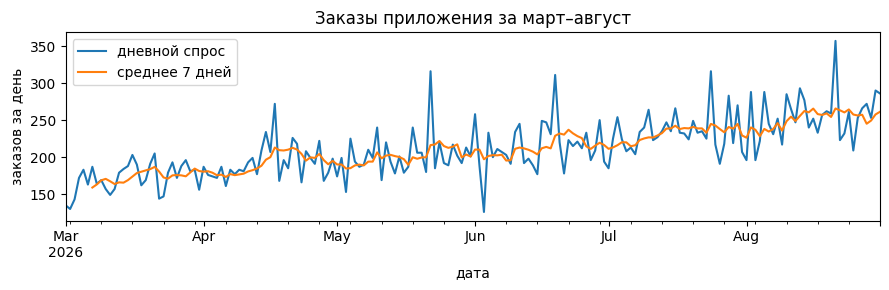

July score740 fixed params 4.037104807877702


August baseline/model/meets 4.352592386598011 4.226666454385134 True


In [4]:
daily=s.resample('D').sum()
fig,ax=plt.subplots(figsize=(9,3))
daily.plot(ax=ax,label='дневной спрос')
daily.rolling(7).mean().plot(ax=ax,label='среднее 7 дней')
ax.set(title='Заказы приложения за март–август',xlabel='дата',ylabel='заказов за день')
ax.legend()
fig.tight_layout()
fig.savefig('native-demand.png')
plt.show()
def error(a,b): return float(np.sqrt(np.mean((np.asarray(a)-np.asarray(b))**2)))
fixed_validation=HistGradientBoostingRegressor(random_state=RANDOM_STATE,**best_params).fit(X[fit_valid],y[fit_valid])
valid_rmse_fixed=error(y[valid_score],np.clip(fixed_validation.predict(X[valid_score]),0,None))
print('July score740 fixed params',valid_rmse_fixed)
model=HistGradientBoostingRegressor(random_state=RANDOM_STATE,**best_params).fit(X[fit_final],y[fit_final])
qmodel=HistGradientBoostingRegressor(loss='quantile',quantile=.8,random_state=RANDOM_STATE,**best_params).fit(X[fit_final],y[fit_final])
# Каждый дневной выпуск сохраняется без y до присоединения фактов
Path('issued').mkdir(exist_ok=True)
issued_frames=[]
for day in pd.date_range('2026-08-01','2026-08-31',freq='D'):
    cutoff=day-pd.Timedelta(hours=5)
    index=pd.date_range(day,periods=24,freq='h')
    history=s.loc[:cutoff]
    assert history.index.max()==cutoff
    release_X=build_X(history,index)
    assert len(release_X)==24 and release_X.notna().all().all()
    assert np.allclose(release_X,X.loc[index])
    frame=pd.DataFrame({'model':np.clip(model.predict(release_X),0,None),'quantile':np.clip(qmodel.predict(release_X),0,None),'baseline':release_X.mean4w,'cutoff':cutoff,'issue':day-pd.Timedelta(hours=4)},index=index)
    assert 'fact' not in frame.columns
    frame.to_csv(Path('issued')/(day.strftime('%Y-%m-%d')+'.csv'))
    issued_frames.append(frame)
issued_forecasts=pd.concat(issued_frames)
assert len(issued_forecasts)==744 and issued_forecasts.index.is_unique
# Факты присоединяются только к уже сохранённым выпускам
scored=issued_forecasts.join(s.rename('fact'))
pred_test=scored.model.to_numpy()
pq=scored['quantile'].to_numpy()
rmse_base=error(scored.fact,scored.baseline)
rmse_final=error(scored.fact,pred_test)
meets=bool(rmse_final<=4.3 and rmse_final<rmse_base)
print('August baseline/model/meets',rmse_base,rmse_final,meets)


**Вывод по анализу.** Входы исправлены механически: полный опубликованный календарь и доступная июльская оценка740. Значения нового результата напечатаются после выполнения. Менять историю, семейство и параметры по августовскому результату не буду.

## 5. Штат и рекомендация
Один человек обслуживает 6 заказов в час; минимум один в 07–22. Сравниваю исходное покрытие спроса и нехватку после ceil отдельно. Квантиль .8 обучается с уже выбранными параметрами; его фактическое покрытие проверяю, а не объявляю равным 80%.

In [5]:
yt=y[test]
work=(yt.index.hour>=7)&(yt.index.hour<=22)
needed=np.maximum(1,np.ceil(yt.to_numpy()/6)).astype(int)
plans={}
for name,p in [('модель',pred_test),('ориентир',X.loc[test,'mean4w'].to_numpy()),('квантиль',pq)]:
    plan=np.maximum(1,np.ceil(p/6)).astype(int)
    delta=(plan-needed)[work]
    short=float(np.mean(delta<0));extra=int(np.maximum(delta,0).sum());deficit=int(np.maximum(-delta,0).sum())
    plans[name]={'short':short,'extra':extra,'deficit':deficit,'coverage_work':float(np.mean(p[work]>=yt.to_numpy()[work])),'cost':3*deficit+extra}
print(pd.DataFrame(plans).T)
print('Все часы: quantile coverage',np.mean(pq>=yt.to_numpy()))
predictions=pd.DataFrame({'fact':yt,'model':pred_test,'baseline':X.loc[test,'mean4w'],'quantile':pq,'needed':needed,'work':work})
for name,p in [('model',pred_test),('baseline',X.loc[test,'mean4w']),('quantile',pq)]: predictions['staff_'+name]=np.where(work,np.maximum(1,np.ceil(np.asarray(p)/6)),0).astype(int)
predictions.to_csv('native-august-predictions.csv')
future_plan=pd.DataFrame({'orders':scored.loc[future,'model']},index=future)
future_plan['staff']=np.where((future.hour>=7)&(future.hour<=22),np.maximum(1,np.ceil(future_plan.orders/6)),0).astype(int)
future_plan.to_csv('native-issued-2026-08-01.csv')
metrics={'sizes':sizes,'score_hours':int(valid_score.sum()),'valid_rmse_fixed':valid_rmse_fixed,'best_params':best_params,'rmse_base':rmse_base,'rmse_final':rmse_final,'meets':meets,'plans':plans,'coverage_q':float(np.mean(pq>=yt.to_numpy())),'work_hours':int(work.sum())}
Path('native-metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2))
print(future_plan)
# Открытый перенос и кадровые границы проверяются самостоятельно
def staff(a,capacity): return np.maximum(1,np.ceil(np.asarray(a)/capacity)).astype(int)
assert staff([0],6).tolist()==[1]
assert np.where([False],staff([0],6),0).tolist()==[0]
assert staff([8,11],6).tolist()==[2,2]
assert staff([6,7],6).tolist()==[1,2]
assert staff([5,6],5).tolist()==[1,2]
assert staff([5,6],6).tolist()==[1,1]
transfer=[]
for capacity,D,E in [(6,300,100),(5,180,100)]:
    demand=np.array([13,0,10])
    need=staff(demand,capacity)
    for count in [2,3]:
        delta=count-need
        deficit=int(np.maximum(-delta,0).sum())
        extra=int(np.maximum(delta,0).sum())
        transfer.append({'capacity':capacity,'D':D,'E':E,'count':count,'needed':need.tolist(),'deficit':deficit,'extra':extra,'cost':D*deficit+E*extra})
assert [r['cost'] for r in transfer]==[400,300,280,300]
Path('own-transfer-results.json').write_text(json.dumps(transfer,ensure_ascii=False,indent=2))
print('Свой перенос',transfer)


             short  extra  deficit  coverage_work   cost
модель    0.306452  118.0    196.0       0.449597  706.0
ориентир  0.288306  142.0    185.0       0.493952  697.0
квантиль  0.155242  286.0     94.0       0.697581  568.0
Все часы: quantile coverage 0.7405913978494624
                        orders  staff
2026-08-01 00:00:00   1.714558      0
2026-08-01 01:00:00   1.395894      0
2026-08-01 02:00:00   0.883595      0
2026-08-01 03:00:00   0.883595      0
2026-08-01 04:00:00   0.895831      0
2026-08-01 05:00:00   1.096491      0
2026-08-01 06:00:00   2.689195      0
2026-08-01 07:00:00   5.515296      1
2026-08-01 08:00:00  11.596065      2
2026-08-01 09:00:00  14.105237      3
2026-08-01 10:00:00  13.857805      3
2026-08-01 11:00:00  16.234114      3
2026-08-01 12:00:00  15.755308      3
2026-08-01 13:00:00  14.082780      3
2026-08-01 14:00:00  13.711428      3
2026-08-01 15:00:00  12.147171      3
2026-08-01 16:00:00  13.573236      3
2026-08-01 17:00:00  13.608433      3
202

**Вывод для руководителя.** При сохранённых HGB, learning_rate=0.05, max_depth=3, random_state=0 и четырёх полных неделях исправленный календарь дал августовскую RMSE 4.226666 против ориентира 4.352592: порог 4.3 выполнен. На июльских 740 доступных ответах RMSE фиксированной модели равна 4.037. Исходный результат 4.374374 остаётся в прежней заморозке; это исправленный пересчёт уже известного августа, не новый слепой тест.

Для 496 рабочих часов при мощности 6 и ценах дефицита/избытка 3/1 средний план имеет 196 недостающих и 118 лишних бариста-часов, цену 706; ориентир — 185/142 и 697; квантиль — 94/286 и 568. Поэтому улучшение RMSE не сделало средний кадровый план выгоднее действующего правила. Квантиль предлагаю для пилота, но его покрытие спроса в рабочих часах 69.76% и по всем часам 74.06% ниже номинальных 80%; доля рабочих часов с нехваткой после округления равна 15.52%.

Параметры, история, квантиль и цены не подбирались повторно. Полный публичный календарь проверен на будущей сетке без y; каждый из 31 дневного выпуска сохранён по 24 строки до присоединения фактов. Неизвестные часы начиная с текущего 20:00 сохранены в регулярном индексе. Собственный перенос на колл-центр подтвердил выбор трёх операторов при 300/100 и двух при мощности 5 и ценах 180/100. Для персонального расписания и оценки реального эффекта нужны цены, производительность, доступные сотрудники, длительность смен, перерывы и данные об очереди.